In [14]:
# Import required libraries
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:
import yfinance as yf

# Disable timezone cache to avoid SQLite database lock issues
yf.set_tz_cache_location(None)

tickers = ['AAPL', 'MSFT', 'JPM', '^GSPC']

# Download historical price data safely using single-threaded mode
raw_data = yf.download(tickers, start='2019-01-01', end='2024-01-01', threads=False)

# Select Adj Close or Close prices
if 'Adj Close' in raw_data.columns:
    adj_close = raw_data['Adj Close']
else:
    adj_close = raw_data['Close']

# Save data locally as CSV
adj_close.to_csv('prices.csv')

print("Data downloaded successfully and saved to prices.csv!")
adj_close.head()


[*********************100%***********************]  4 of 4 completed


Data downloaded successfully and saved to prices.csv!


Ticker,AAPL,JPM,MSFT,^GSPC
Date,,,,
2019-01-02,37.436920,80.074478,94.016144,2510.030029
2019-01-03,33.707924,78.936493,90.557487,2447.889893
2019-01-04,35.146893,81.846527,94.769241,2531.939941
2019-01-07,35.068668,81.903412,94.890121,2549.689941
2019-01-08,35.737167,81.748978,95.578133,2574.409912


--- First 5 rows of daily returns ---


Ticker,AAPL,JPM,MSFT,^GSPC
Date,,,,
2019-01-03,-0.099607,-0.014212,-0.036788,-0.024757
2019-01-04,0.042689,0.036866,0.046509,0.034336
2019-01-07,-0.002226,0.000695,0.001276,0.007010
2019-01-08,0.019063,-0.001886,0.007251,0.009695
2019-01-09,0.016982,-0.001690,0.014299,0.004098


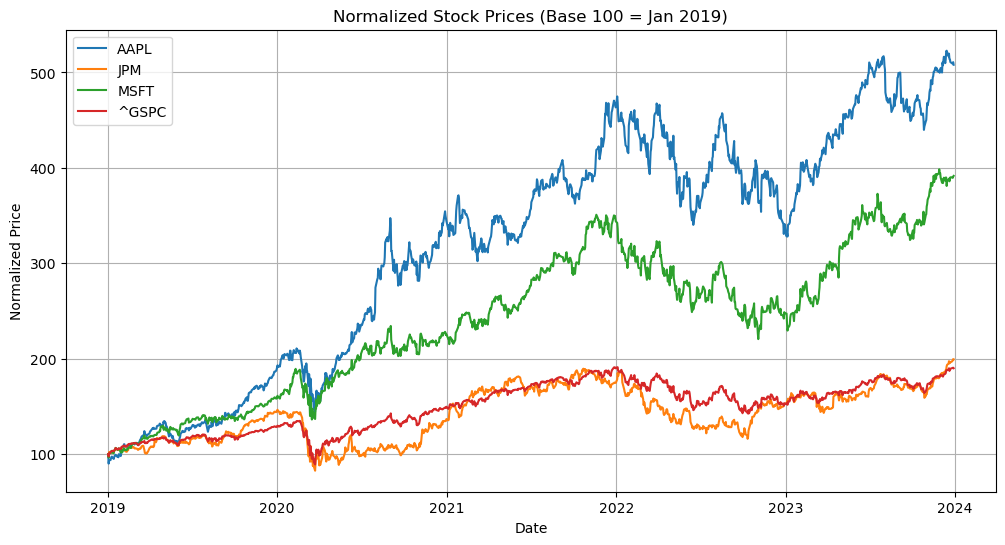

In [16]:
import matplotlib.pyplot as plt

# Calculate daily percentage returns
returns = adj_close.pct_change().dropna()

# Display first 5 rows of returns
print("--- First 5 rows of daily returns ---")
display(returns.head())

# Plot normalized prices starting at base 100
plt.figure(figsize=(12, 6))
normalized_prices = (adj_close / adj_close.iloc[0]) * 100
plt.plot(normalized_prices)
plt.title('Normalized Stock Prices (Base 100 = Jan 2019)')
plt.xlabel('Date')
plt.ylabel('Normalized Price')
plt.legend(normalized_prices.columns, loc='upper left')
plt.grid(True)
plt.show()


In [17]:
import numpy as np

# Assuming 252 trading days per year and a 2% risk-free rate
trading_days = 252
risk_free_rate = 0.02

# 1. Calculate annualized return
annual_return = returns.mean() * trading_days

# 2. Calculate annualized volatility (standard deviation)
annual_volatility = returns.std() * np.sqrt(trading_days)

# 3. Calculate Sharpe ratio
sharpe_ratio = (annual_return - risk_free_rate) / annual_volatility

# Combine results into a summary table
risk_return_summary = pd.DataFrame({
    'Annualized Return (%)': (annual_return * 100).round(2),
    'Annualized Volatility (%)': (annual_volatility * 100).round(2),
    'Sharpe Ratio': sharpe_ratio.round(2)
})

print("=== Risk and Return Summary ===")
display(risk_return_summary)

# Calculate and display the correlation matrix
correlation_matrix = returns.corr().round(2)
print("\n=== Daily Returns Correlation Matrix ===")
display(correlation_matrix)

=== Risk and Return Summary ===


,Annualized Return (%),Annualized Volatility (%),Sharpe Ratio
Ticker,,,
AAPL,37.80,32.23,1.11
JPM,18.90,31.90,0.53
MSFT,32.03,30.49,0.98
^GSPC,15.16,21.32,0.62



=== Daily Returns Correlation Matrix ===


Ticker,AAPL,JPM,MSFT,^GSPC
Ticker,,,,
AAPL,1.00,0.45,0.76,0.80
JPM,0.45,1.00,0.45,0.73
MSFT,0.76,0.45,1.00,0.83
^GSPC,0.80,0.73,0.83,1.00


In [18]:
from arch import arch_model
import numpy as np

# Select AAPL returns (multiply by 100 for arch convergence)
r = returns['AAPL'].dropna() * 100

# Fit GARCH(1,1) model
model = arch_model(r, p=1, q=1)
result = model.fit(disp='off')

# Print summary
print(result.summary())

# Forecast 1 day ahead
forecast = result.forecast(horizon=1)
daily_vol = np.sqrt(forecast.variance.iloc[-1, 0])
annual_vol = daily_vol * np.sqrt(252)

print("\n--- Volatility Forecast ---")
print("Next-day daily vol (%):", round(daily_vol, 2))
print("Next-day annualized vol (%):", round(annual_vol, 2))


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   AAPL   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2520.15
Distribution:                  Normal   AIC:                           5048.30
Method:            Maximum Likelihood   BIC:                           5068.84
                                        No. Observations:                 1257
Date:                Sun, Oct 18 2026   Df Residuals:                     1256
Time:                        22:17:52   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.2369  4.937e-02      4.798  1.599e-06 [  0.140,  0.33

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pandas as pd

# Prepare volatility proxy (absolute returns)
df_ml = pd.DataFrame({'vol': returns['AAPL'].abs()})

# Feature: lag 1 day and lag 5 days
df_ml['vol_lag1'] = df_ml['vol'].shift(1)
df_ml['vol_lag5'] = df_ml['vol'].shift(5)
df_ml = df_ml.dropna()

# Train / Test split (80% train, 20% test)
split_idx = int(len(df_ml) * 0.8)
X = df_ml[['vol_lag1', 'vol_lag5']]
y = df_ml['vol']

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Fit Random Forest model
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict on test set
y_pred = rf.predict(X_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print("=== Machine Learning (Random Forest) Results ===")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))


=== Machine Learning (Random Forest) Results ===
MAE: 0.0089
RMSE: 0.0113
